In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [2]:
def V(x, k=1): # Potential from task
    return 0.5 *k*x**2

def P(x, k=1, kT=.15):
    return np.sqrt(k / (2*np.pi*kT)) * np.exp(-V(x,k=k) / kT)


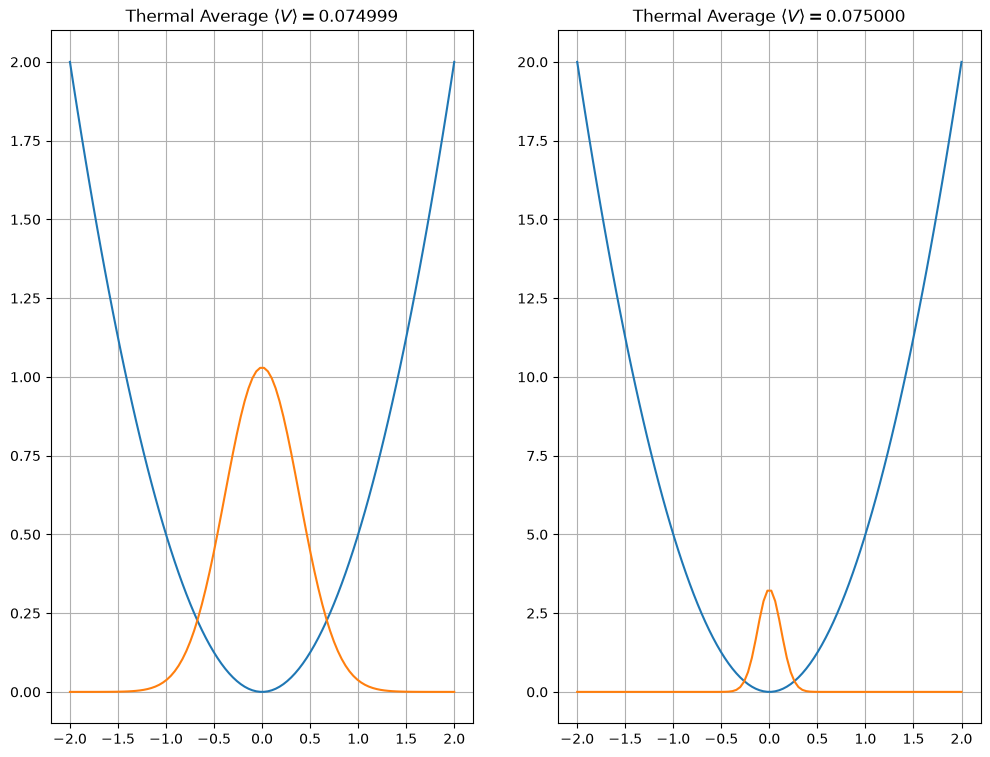

In [7]:
x_min = -2
x_max = 2
xs = np.linspace(x_min,x_max, 100)
fig, axes = plt.subplots(1,2, figsize=(12,9))

thermal_average_k1 = quad(lambda x: V(x, k=1)*P(x, k=1), x_min, x_max)[0]
thermal_average_k10 = quad(lambda x: V(x, k=10)*P(x, k=10), x_min, x_max)[0]

axes[0].plot(xs, V(xs))
axes[0].plot(xs, P(xs))
axes[0].set_title(rf"Thermal Average $\langle V \rangle = {thermal_average_k1:.6f}$")
axes[0].grid()

axes[1].plot(xs, V(xs, k=10))
axes[1].plot(xs, P(xs, k=10))
axes[1].grid()
axes[1].set_title(rf"Thermal Average $\langle V \rangle = {thermal_average_k10:.6f}$")

thermal_average_k1 = quad(lambda x: V(x, k=1)*P(x, k=1), x_min, x_max)
thermal_average_k10 = quad(lambda x: V(x, k=10)*P(x, k=10), x_min, x_max)


In [ ]:
# Rejection-Sampling
def generate_sample(x_min, x_max, N=10000):
    xs = np.linspace(x_min, x_max, N)
    envelope = P(xs)
    p_max = np.max(envelope)
    return [x for x, p in zip[xs, envelope if np.random.rand() < (p/p_max)]]

def get_thermal_average_from_sample(sample):
    return 1 / N * sum(sample)